In [1]:
import tensorflow as tf
import keras
print(tf.__version__)
print(keras.__version__)

2.21.0
3.15.1


#IMport libraries and locate dataset

In [2]:
from pathlib import Path
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image


ROOT = Path.cwd()
DATA = ROOT.parent / "data"
IMG_SIZE = (128,128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print("tensorflow version:", tf.__version__)
print("dataset found", DATA.is_dir(), "| Folder path:", DATA)

print("ROOT:",ROOT)
print("DATA:",DATA)
print("DATA exists:",DATA.exists())

tensorflow version: 2.21.0
dataset found True | Folder path: c:\Users\ASUS\Downloads\GrowTech\cnn prc\data
ROOT: c:\Users\ASUS\Downloads\GrowTech\cnn prc\data
DATA: c:\Users\ASUS\Downloads\GrowTech\cnn prc\data
DATA exists: True


#check the class folders (x and y) in the dataset directory

In [3]:

# Define only the three actual disease classes
class_names = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

classes=class_names

print("Correct class names:", class_names)

print("Number of class names:", len(class_names))
print("Class names:", class_names)

counts = {}

for name in classes:
    folder = DATA / name

    counts[name] = len([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png"]
    ]) if folder.is_dir() else 0

print("Images per class:", counts)

assert len(classes) == 3 and all(
    v > 0 for v in counts.values()
), "Dataset folders missing or empty!"

print("All three classes verified successfully!")





Correct class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Number of class names: 3
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Images per class: {'Potato___Early_blight': 999, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}
All three classes verified successfully!


#  display three real images : open actual file per class , converts it into RGB and display it.

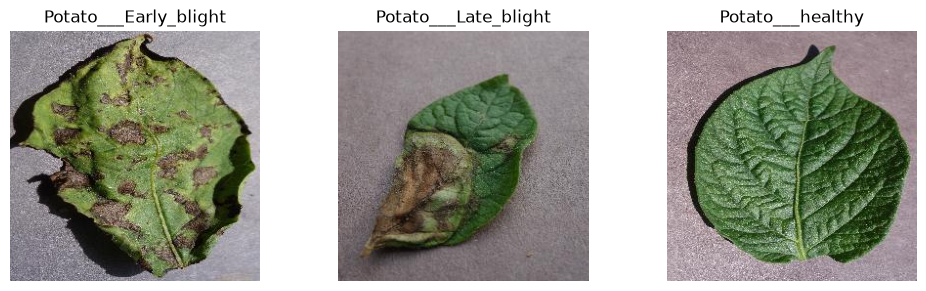

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for i, name in zip(axes, classes):
    folder = DATA/name
    file=next(p for p in folder.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
    with Image.open(file) as img:
        img = img.convert("RGB")
        i.imshow(img)
        i.set_title(name)
        i.axis("off")   
plt.tight_layout()
plt.show()
    

#ADDED (new cell): create a separate test set. Run this cell ONLY ONCE.

load images , resize , split  into train /validation

In [5]:

# Define only the three potato disease classes
class_names = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    class_names=class_names
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    class_names=class_names
)

# Display dataset information
images, labels = next(iter(train_ds))

print("Class order:", class_names)
print("Images in one batch:", images.shape)
print("Labels in one batch:", labels[:32].numpy())


Found 2151 files belonging to 3 classes.
Using 1721 files for training.
Found 2151 files belonging to 3 classes.
Using 430 files for validation.
Class order: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Images in one batch: (32, 128, 128, 3)
Labels in one batch: [0 0 0 1 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 0 0 0 0 1 0 0 1 1 0 1 0 1]


data augmentation : rotation , zoom , horizontal flip , vertical flip  and scaling 

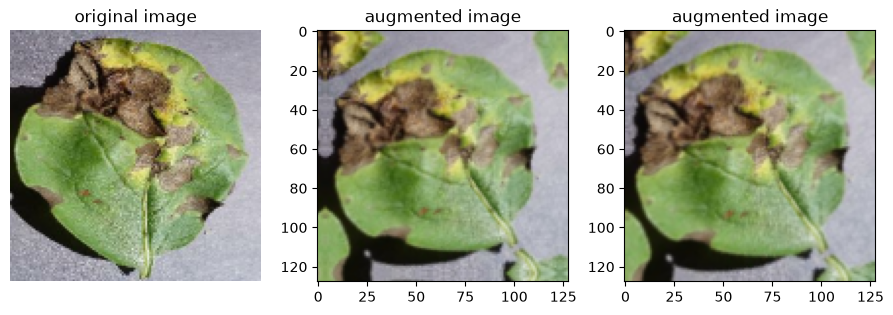

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"), 
    tf.keras.layers.RandomRotation(0.1,fill_mode="reflect"),                  
    tf.keras.layers.RandomZoom(0.1,fill_mode="reflect"), 
    #tf.keras.layers.RandomContrast(0.1)                    
])

sample=images[0:1]
fig , axes = plt.subplots(1,3, figsize=(9,3))
axes[0].imshow(tf.cast(sample[0], tf.uint8 ))
axes[0].set_title("original image")

for i in (1,2):
    augmented=augmentation(sample,training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(augmented, 0,255),tf.uint8))

    axes[i].set_title("augmented image") 

for i in axes:
    i.axis("off")
    plt.tight_layout()
    plt.show()
    



cnn layers : 1.feature_extractor(conv2d,maxpooling2d),2.(flatten),3.classifier(dense+dropout+softmax)

In [7]:
model=tf.keras.Sequential([
    tf.keras.Input(shape=(128,128,3)),
    tf.keras.layers.Rescaling(1.0/255),
    augmentation,

    #  feature extractor
    tf.keras.layers.Conv2D(32,3 , padding= "same", use_bias=False), 
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(64,3 ,padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),



    tf.keras.layers.Conv2D(128,3 ,padding="same",use_bias=False ),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256,3 ,padding="same",use_bias=False ),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    # flatten
    tf.keras.layers.GlobalAveragePooling2D(), 


    # classifier
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(3, activation="softmax")


])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:

# Get all training labels
train_labels = np.concatenate([
    y.numpy() for _, y in train_ds
])

# Handle one-hot encoded labels
if train_labels.ndim > 1:
    train_labels = np.argmax(train_labels, axis=1)

# Convert labels to integer format
train_labels = train_labels.astype(np.int32).flatten()

# Calculate class counts
class_counts = np.bincount(
    train_labels,
    minlength=len(class_names)
)


# Display class distribution
print("Class names:", class_names)
print("\nTraining class counts:")

for i, count in enumerate(class_counts):
    print(f"{i}: {class_names[i]} = {count}")

# Check for missing classes
if np.any(class_counts == 0):
    missing_classes = [
        class_names[i]
        for i, count in enumerate(class_counts)
        if count == 0
    ]

    raise ValueError(
        f"Some classes have zero training images: {missing_classes}. "
        "Please check your dataset folders."
    )

# Calculate balanced class weights
class_weights = {
    i: float(len(train_labels) / (len(class_names) * count))
    for i, count in enumerate(class_counts)
}

print("\nUpdated class weights:", class_weights)

#apply callback (model_checkpoints)

callbacks_list=[
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1

    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

model.compile(
    optimizer=Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks_list
)

Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

Training class counts:
0: Potato___Early_blight = 816
1: Potato___Late_blight = 791
2: Potato___healthy = 114

Updated class weights: {0: 0.7030228758169934, 1: 0.7252423093131057, 2: 5.0321637426900585}
Epoch 1/15


c:\Users\ASUS\Downloads\GrowTech\cnn prc\data\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 48s 796ms/step - accuracy: 0.8716 - loss: 0.3214 - val_accuracy: 0.7953 - val_loss: 0.5144 - learning_rate: 0.0010
Epoch 2/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 42s 778ms/step - accuracy: 0.9285 - loss: 0.2088 - val_accuracy: 0.6488 - val_loss: 1.6488 - learning_rate: 0.0010
Epoch 3/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.9204 - loss: 0.2199
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
54/54 ━━━━━━━━━━━━━━━━━━━━ 42s 773ms/step - accuracy: 0.9204 - loss: 0.2199 - val_accuracy: 0.5047 - val_loss: 3.3692 - learning_rate: 0.0010
Epoch 4/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 83s 783ms/step - accuracy: 0.9500 - loss: 0.1276 - val_accuracy: 0.6605 - val_loss: 1.4378 - learning_rate: 5.0000e-04
Epoch 5/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 725ms/step - accuracy: 0.9512 - loss: 0.1199
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
54/54 ━━━━━━━━━━━━━━━━━━━━ 42s 769ms/step - accuracy: 0.9512 - loss: 0.1199 - val_

In [14]:

# Define only the three actual disease classes
class_names = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

print("Correct class names:", class_names)

print("Number of class names:", len(class_names))
print("Class names:", class_names)

print("\nClass counts:", class_counts)
print("Length of class_counts:", len(class_counts))

print("\nUnique training labels:", np.unique(train_labels))
print("Maximum training label:", np.max(train_labels))


Correct class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Number of class names: 3
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

Class counts: [816 791 114]
Length of class_counts: 3

Unique training labels: [0 1 2]
Maximum training label: 2


training and validation graphs

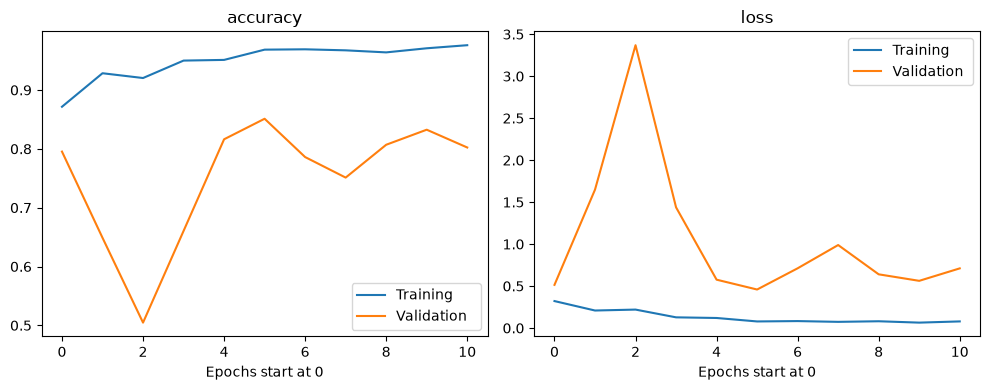

In [15]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training  ') 
plt.plot(history.history['val_accuracy'], label='Validation  ')
plt.title('accuracy')
plt.xlabel('Epochs start at 0')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training ')
plt.plot(history.history['val_loss'], label='Validation ')
plt.title('loss')
plt.xlabel('Epochs start at 0')
plt.legend()    


plt.tight_layout()
plt.show()


confusion matrix and classification report

validation accuracy:0.85 not test accuracy


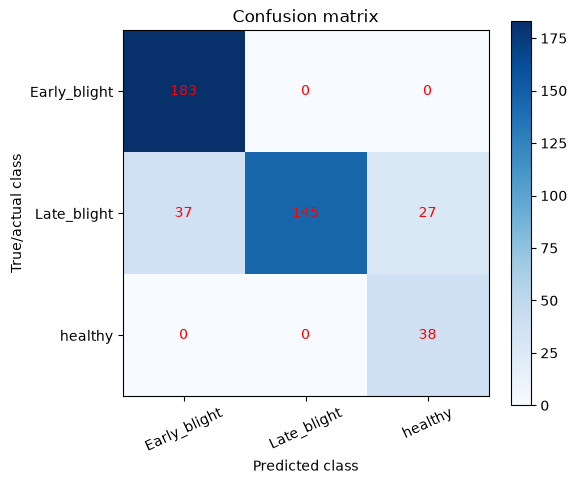

In [16]:
all_true,all_pred=[],[]
for batch_images,batch_labels in val_ds:
    scores=model.predict(batch_images,verbose=0)
    all_true.extend(batch_labels.numpy())
    all_pred.extend(np.argmax(scores,axis=1))

matrix=tf.math.confusion_matrix(all_true,all_pred,num_classes=len(class_names)).numpy()

accuracy=np.mean(np.array(all_true)==np.array(all_pred))
print(f"validation accuracy:{accuracy:.2f} not test accuracy")


# CHANGED: prefix fixed (your names use "Potato___", not "potato__")
short_names=[s.replace("Potato___","") for s in class_names]

plt.figure(figsize=(6,5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(3),short_names,rotation=25)
plt.yticks(range(3),short_names) 
plt.xlabel("Predicted class")
plt.ylabel("True/actual class")
plt.title("Confusion matrix")  


for i in range(3):
    for j in range(3):
        plt.text(j,i, matrix[i,j], ha="center", va="center", color="red")
plt.tight_layout()
plt.show()
        


In [17]:
model.save("potato_cnn_model.keras")
Path("classification_report.txt").write_text("\n".join(class_names),encoding="utf-8")
print("model saved to potato_cnn_model.keras and class names saved to classification_report.txt")

model saved to potato_cnn_model.keras and class names saved to classification_report.txt


unseen data prediction and check accuracy

model score 1.00
Early_blight : 1.00
Late_blight : 0.00
healthy : 0.00


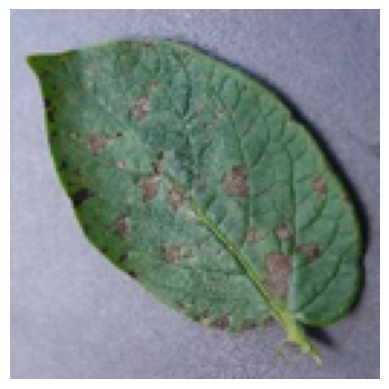

In [18]:
image_path = ROOT / "leaf.JPG"
if image_path.is_file():
    with Image.open(image_path) as file:
        image = file.convert("RGB").resize(IMG_SIZE)
    x=np.expand_dims(np.array(image,dtype=np.float32),axis=0)
    scores=model.predict(x,verbose=0)[0]
    best= int(np.argmax(scores))
    print("model score",f"{scores[best]:.2f}")
    for name, score in zip(class_names,scores):
        print(f"{name.replace('Potato___','')} : {score:.2f}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print(" place an image named leaf.jpg beside this notebook and run cell again")
                     

#hyperparametr tuning

dropout
learning_rate 
class_weight
epoch

batch normilization   
model_check_point     